# 03 · Neural Collapse metrics (NC1–NC4) across training

For each of the 113 checkpoints from `01_train_resnet18_cifar10.ipynb`, this notebook measures the four Neural Collapse (NC) properties (Papyan, Han & Donoho, 2020) on the 512-d penultimate features (the `avgpool` output that feeds the final linear layer), then computes when each metric stabilizes.

| Metric | What it measures | Definition used here | Collapsed value |
|---|---|---|---|
| **NC1** | within-class variability | $\sigma_W^2/\sigma_B^2$, with $\sigma_W^2=\frac1N\sum_i\lVert h_i-\mu_{y_i}\rVert^2$, $\sigma_B^2=\frac1C\sum_c\lVert\mu_c-\mu_G\rVert^2$ | 0 |
| **NC2** | simplex-ETF geometry of class means | $\sqrt{E_{angle}^2+E_{norm}^2}$; $E_{angle}$ = RMS of $G-G_{ETF}$ (cosine Gram of centered means vs. simplex ETF), $E_{norm}$ = relative std of the centered-mean norms | 0 |
| **NC3** | self-duality (classifier ≈ class means) | $\lVert W/\lVert W\rVert_F-\tilde M/\lVert\tilde M\rVert_F\rVert_F$ ("NC3 formal") | 0 |
| **NC4** | classifier ≡ nearest-class-center | fraction of **test** images where the network's prediction ≠ nearest *training* class mean | 0 |

**Data**
- NC1–NC3: all 50,000 CIFAR-10 training images.
- NC4: the 10,000 test images (network prediction vs. nearest class mean computed on the training features).
- `AUGMENT_TRAIN_FEATURES = True` reproduces the original experiment, in which the training features were extracted with the *training* transform (random crop + horizontal flip), model in `eval()` mode. Set it to `False` to use clean, deterministic training images instead (results are saved with a `_clean` suffix).

**Stabilization epoch** (same strict rule for every metric): the first checkpoint from which the metric stays ≤ threshold for *all* later checkpoints. Threshold = 1.2 × final value for NC1, NC2 (and its angular/norm parts) and NC3. For NC4 an absolute threshold of 0.01 (1 % disagreement) is used, because its final value is ≈ 4/10,000 and 1.2 × that is below the checkpoint-to-checkpoint noise.

**Input:** `checkpoints/epoch_{N}.pth` from notebook 01  
**Outputs:** `NC_results.csv`, `NC_stabilization_summary.csv`, figures

In [1]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, models, transforms

## Configuration

In [6]:
ON_KAGGLE = os.path.exists("/kaggle/working")

# Folder containing epoch_{N}.pth files produced by notebook 01.
# On Kaggle, point this at the dataset / notebook output that holds the checkpoints, e.g.
#   CHECKPOINT_DIR = Path("/kaggle/input/<your-dataset>/checkpoints")
BASE = Path(
    "/kaggle/input/notebooks/parinazghasemi/train-more-epochs"
)

CHECKPOINT_DIR = BASE / "checkpoints"

FINAL_MODEL = BASE / "final_model.pth"

HISTORY = BASE / "training_history.csv"

DATA_DIR = (
    "/kaggle/input/"
    "notebooks/parinazghasemi/"
    "train-epochs/data"
)

OUTPUT_DIR = Path("/kaggle/working" if ON_KAGGLE else ".")

SEED = 42
BATCH_SIZE = 256
NUM_WORKERS = 2
FINAL_EPOCH = 350

# True  -> training features extracted with random crop + flip (original experiment)
# False -> clean training images (deterministic)
AUGMENT_TRAIN_FEATURES = True
SUFFIX = "" if AUGMENT_TRAIN_FEATURES else "_clean"

RESULTS_FILE = OUTPUT_DIR / f"NC_results{SUFFIX}.csv"
SUMMARY_FILE = OUTPUT_DIR / f"NC_stabilization_summary{SUFFIX}.csv"

STABILITY_FACTOR = 1.2      # threshold = 1.2 x final value
NC4_ABS_THRESHOLD = 0.01    # absolute threshold for NC4

COLUMNS = ["epoch", "NC1", "NC2", "NC2_angular", "NC2_norm", "NC3_formal", "NC4"]

# The 113 checkpointed epochs (must match notebook 01)
EPOCHS = sorted(set(
    list(range(1, 21))
    + list(range(25, 101, 5))
    + list(range(110, 221, 10))
    + list(range(220, 351, 2))
))

missing = [e for e in EPOCHS if not (CHECKPOINT_DIR / f"epoch_{e}.pth").exists()]
assert not missing, f"{len(missing)} checkpoints not found in {CHECKPOINT_DIR}, e.g. {missing[:5]}"
print(f"Found all {len(EPOCHS)} checkpoints.")

Found all 113 checkpoints.


In [7]:
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


## Data

In [8]:
NORM = transforms.Normalize((0.4914, 0.4822, 0.4465), (0.2023, 0.1994, 0.2010))

transform_test = transforms.Compose([transforms.ToTensor(), NORM])
transform_train = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    NORM,
])

train_dataset = datasets.CIFAR10(root=DATA_DIR, train=True, download=True,
                                 transform=transform_train if AUGMENT_TRAIN_FEATURES else transform_test)
test_dataset = datasets.CIFAR10(root=DATA_DIR, train=False, download=True, transform=transform_test)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=NUM_WORKERS, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=NUM_WORKERS, pin_memory=True)

print("Train samples:", len(train_dataset), "| Test samples:", len(test_dataset))
print("Classes:", train_dataset.classes)

Train samples: 50000 | Test samples: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## Model and feature extraction

In [9]:
model = models.resnet18(num_classes=10)
model.conv1 = nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1, bias=False)
model.maxpool = nn.Identity()
model = model.to(device)

FEATURES = {}
model.avgpool.register_forward_hook(lambda module, inp, out: FEATURES.__setitem__("avgpool", out))


def load_checkpoint(epoch):
    ckpt = torch.load(CHECKPOINT_DIR / f"epoch_{epoch}.pth", map_location=device)
    model.load_state_dict(ckpt["model_state_dict"])
    model.eval()


@torch.no_grad()
def extract(loader, with_logits=False):
    """Return (features [N,512], labels [N], logits [N,10] or None) as CPU tensors."""
    model.eval()
    feats, labels, logits = [], [], []
    for x, y in loader:
        out = model(x.to(device, non_blocking=True))
        feats.append(FEATURES["avgpool"].flatten(start_dim=1).cpu())
        labels.append(y)
        if with_logits:
            logits.append(out.cpu())
    return (
        torch.cat(feats),
        torch.cat(labels),
        torch.cat(logits) if with_logits else None,
    )

## Metric definitions

In [10]:
def class_statistics(features, labels):
    features, labels = features.float(), labels.long()
    classes = torch.unique(labels)
    class_means = torch.stack([features[labels == c].mean(dim=0) for c in classes])  # [C, D]
    global_mean = features.mean(dim=0)                                                # [D]
    return classes, class_means, global_mean


@torch.no_grad()
def compute_nc1_nc2(features, labels):
    features, labels = features.float(), labels.long()
    classes, class_means, global_mean = class_statistics(features, labels)
    C = len(classes)
    centered_means = class_means - global_mean

    # NC1: within-class variance / between-class variance
    within = torch.stack([
        (features[labels == c] - class_means[i]).pow(2).sum() for i, c in enumerate(classes)
    ]).sum() / features.shape[0]
    between = centered_means.pow(2).sum() / C
    nc1 = within / (between + 1e-12)

    # NC2: equal norms + simplex-ETF angles
    norms = centered_means.norm(dim=1)
    mean_norm = norms.mean()
    norm_error = ((norms - mean_norm) / (mean_norm + 1e-12)).pow(2).mean().sqrt()

    unit_means = centered_means / (norms.unsqueeze(1) + 1e-12)
    G = unit_means @ unit_means.T
    etf = torch.full_like(G, -1.0 / (C - 1))
    etf.fill_diagonal_(1.0)
    angular_error = (G - etf).pow(2).mean().sqrt()          # RMS over the C x C entries

    nc2 = torch.sqrt(angular_error.pow(2) + norm_error.pow(2))
    return {
        "NC1": nc1.item(),
        "NC2": nc2.item(),
        "NC2_angular": angular_error.item(),
        "NC2_norm": norm_error.item(),
    }


@torch.no_grad()
def compute_nc3_formal(features, labels, fc_weight):
    _, class_means, global_mean = class_statistics(features, labels)
    centered_means = class_means - global_mean               # [C, D]
    W = fc_weight.detach().float().cpu()                     # [C, D]
    W_hat = W / (W.norm() + 1e-12)                           # Frobenius-normalised
    M_hat = centered_means / (centered_means.norm() + 1e-12)
    return (W_hat - M_hat).norm().item()


@torch.no_grad()
def compute_nc4(test_features, test_logits, train_class_means):
    ncc_pred = torch.cdist(test_features.float(), train_class_means.float()).argmin(dim=1)
    net_pred = test_logits.argmax(dim=1)
    return (net_pred != ncc_pred).float().mean().item()

## Compute all metrics for every checkpoint
One pass over the training set and one over the test set per checkpoint. Results are written after every epoch, so an interrupted run resumes where it stopped.

In [11]:
if RESULTS_FILE.exists():
    done = pd.read_csv(RESULTS_FILE)
    print(f"Resuming: {len(done)} epochs already done.")
else:
    done = pd.DataFrame(columns=COLUMNS)

rows = {int(r["epoch"]): [r[c] for c in COLUMNS[1:]] for _, r in done.iterrows()}

for epoch in tqdm([e for e in EPOCHS if e not in rows]):
    load_checkpoint(epoch)

    torch.manual_seed(SEED + epoch)   # reproducible augmentation draws for this checkpoint
    train_feats, train_labels, _ = extract(train_loader)
    test_feats, _, test_logits = extract(test_loader, with_logits=True)

    m = compute_nc1_nc2(train_feats, train_labels)
    nc3 = compute_nc3_formal(train_feats, train_labels, model.fc.weight)
    _, train_means, _ = class_statistics(train_feats, train_labels)
    nc4 = compute_nc4(test_feats, test_logits, train_means)

    rows[epoch] = [m["NC1"], m["NC2"], m["NC2_angular"], m["NC2_norm"], nc3, nc4]

    pd.DataFrame(
        [[e] + v for e, v in sorted(rows.items())], columns=COLUMNS
    ).to_csv(RESULTS_FILE, index=False)

  0%|          | 0/113 [00:00<?, ?it/s]

## Results

In [12]:
nc = pd.read_csv(RESULTS_FILE).sort_values("epoch").reset_index(drop=True)
print("Rows:", len(nc), "| missing epochs:", sorted(set(EPOCHS) - set(nc["epoch"])))
nc.iloc[[0, len(nc) // 2, -1]]

Rows: 113 | missing epochs: []


,epoch,NC1,NC2,NC2_angular,NC2_norm,NC3_formal,NC4
0,1,2.171776,0.702723,0.667214,0.220555,0.909032,0.3457
56,238,0.211585,0.130782,0.102500,0.081226,0.190646,0.0181
112,350,0.020923,0.065935,0.062875,0.019853,0.145762,0.0004


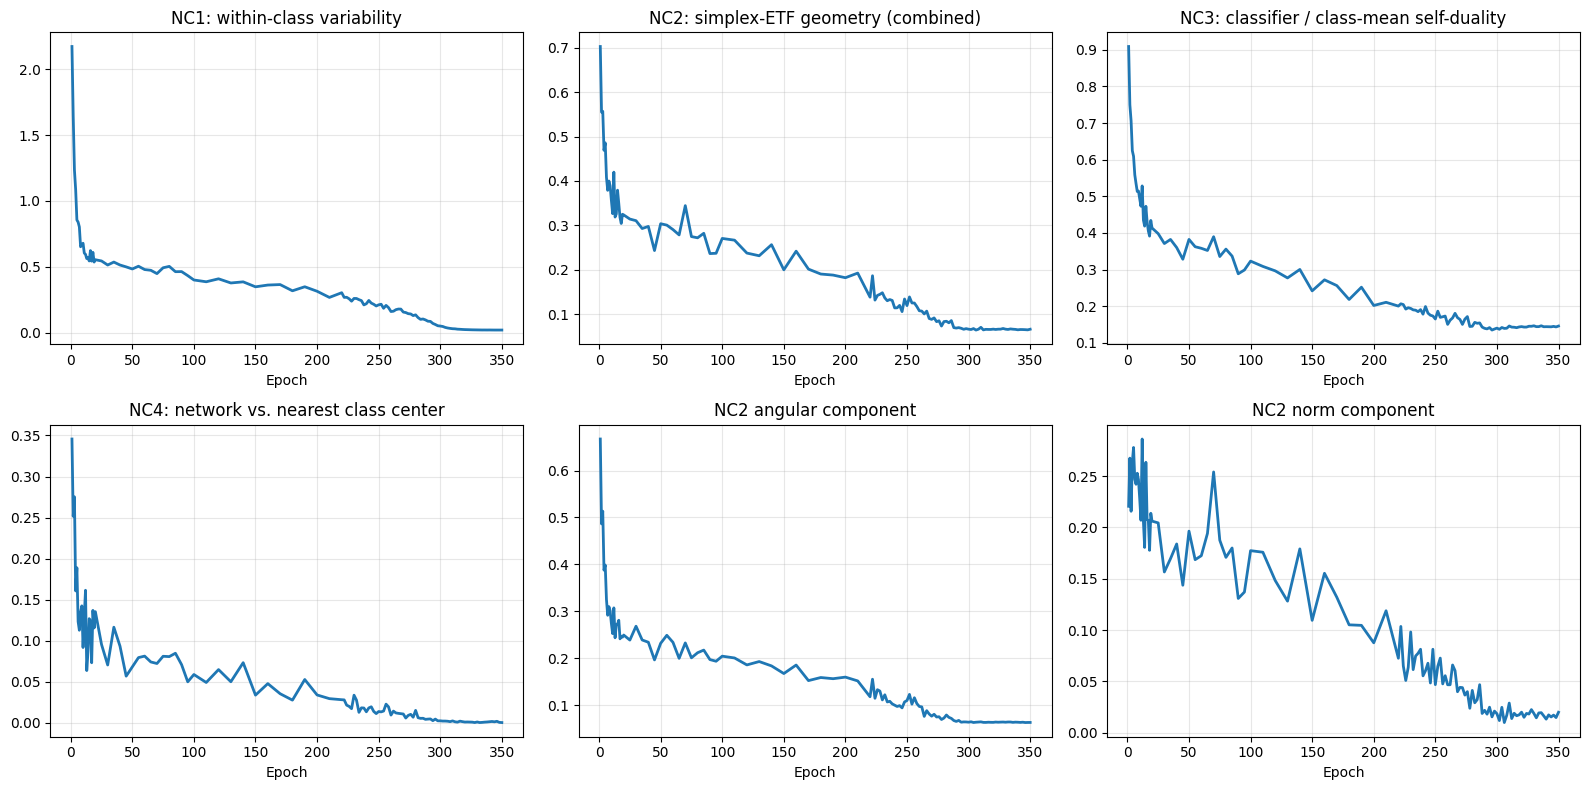

In [13]:
panels = [
    ("NC1", "NC1: within-class variability"),
    ("NC2", "NC2: simplex-ETF geometry (combined)"),
    ("NC3_formal", "NC3: classifier / class-mean self-duality"),
    ("NC4", "NC4: network vs. nearest class center"),
    ("NC2_angular", "NC2 angular component"),
    ("NC2_norm", "NC2 norm component"),
]
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, (col, title) in zip(axes.ravel(), panels):
    ax.plot(nc["epoch"], nc[col], linewidth=2)
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / f"nc_metrics{SUFFIX}.png", dpi=200)
plt.show()

## Stabilization epochs (strict rule)

In [14]:
def strict_stabilization_below(epochs, values, threshold):
    """First epoch from which values stay <= threshold until the end of training."""
    epochs, values = np.asarray(epochs), np.asarray(values)
    for i in range(len(values)):
        if np.all(values[i:] <= threshold):
            return int(epochs[i])
    return None


records = []
for col in ["NC1", "NC2", "NC2_angular", "NC2_norm", "NC3_formal"]:
    final = nc[col].iloc[-1]
    thr = STABILITY_FACTOR * final
    records.append({"metric": col, "final_value": final, "threshold": thr,
                    "stabilization_epoch": strict_stabilization_below(nc["epoch"], nc[col], thr)})

final4 = nc["NC4"].iloc[-1]
records.append({"metric": "NC4", "final_value": final4, "threshold": NC4_ABS_THRESHOLD,
                "stabilization_epoch": strict_stabilization_below(nc["epoch"], nc["NC4"], NC4_ABS_THRESHOLD)})

summary = pd.DataFrame(records)
summary.to_csv(SUMMARY_FILE, index=False)
summary

,metric,final_value,threshold,stabilization_epoch
0,NC1,0.020923,0.025108,320
1,NC2,0.065935,0.079122,288
2,NC2_angular,0.062875,0.075450,284
3,NC2_norm,0.019853,0.023824,312
4,NC3_formal,0.145762,0.174915,268
5,NC4,0.000400,0.010000,282
